# 03 – Aerosols and air quality from CAMS

**CAMS global reanalysis (EAC4)** is produced by the Copernicus Atmosphere
Monitoring Service at ECMWF. It combines a chemistry/aerosol model with
satellite observations (for example aerosol optical depth from MODIS) and gives
3-hourly fields on a 0.75° grid (Inness et al., 2019).

Variables used here:

| Short name | Meaning | Unit |
|---|---|---|
| `aod550` | total aerosol optical depth at 550 nm | – |
| `duaod550` | part of the AOD caused by **dust** | – |
| `pm2p5`, `pm10` | mass of particles smaller than 2.5 / 10 µm near the surface | kg m⁻³ |
| `tcco` | total column carbon monoxide | kg m⁻² |

AOD tells us how much sunlight is removed by particles in the whole atmospheric
column. AOD ≈ 0.1 is a clean sky, AOD > 0.5 is a very hazy or dusty sky.

In [1]:
import sys
sys.path.append("../scripts")

import matplotlib.pyplot as plt
import xarray as xr

import config as cfg
from helpers import COLORS, GREY, PLATE, map_axes, open_cams, open_era5, plot_field, save

cams = open_cams()
cams

<xarray.Dataset> Size: 4MB
Dimensions:    (time: 240, latitude: 21, longitude: 40)
Coordinates:
  * time       (time) datetime64[ns] 2kB 2023-04-01 ... 2023-04-30T21:00:00
  * latitude   (latitude) float64 168B 45.0 44.25 43.5 42.75 ... 31.5 30.75 30.0
  * longitude  (longitude) float64 320B 20.25 21.0 21.75 ... 48.0 48.75 49.5
Data variables:
    aod550     (time, latitude, longitude) float32 806kB ...
    duaod550   (time, latitude, longitude) float32 806kB ...
    pm2p5      (time, latitude, longitude) float32 806kB ...
    pm10       (time, latitude, longitude) float32 806kB ...
    tcco       (time, latitude, longitude) float32 806kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-21T17:58 GRIB to CDM+CF via cfgrib-0.9.1...

PM values are stored in kg m⁻³. Air-quality limits are given in µg m⁻³,
so we multiply by 10⁹. Xarray keeps the coordinates when we do maths with the
arrays, and we update the `units` attribute ourselves.

In [2]:
for v in ("pm2p5", "pm10"):
    cams[v] = cams[v] * 1e9
    cams[v].attrs["units"] = "µg m-3"

cams["dust_fraction"] = cams.duaod550 / cams.aod550
print(cams[["aod550", "duaod550", "pm10"]].mean().compute())

<xarray.Dataset> Size: 12B
Dimensions:   ()
Data variables:
    aod550    float32 4B 0.2429
    duaod550  float32 4B 0.08948
    pm10      float32 4B 36.29
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-21T17:58 GRIB to CDM+CF via cfgrib-0.9.1...


## Monthly mean maps

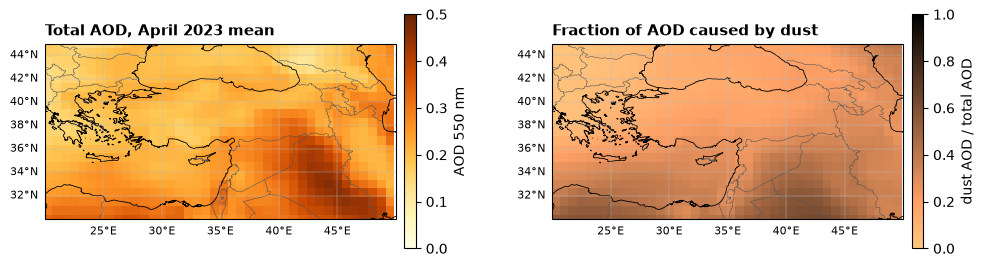

In [3]:
fig, axes = map_axes(1, 2, figsize=(12, 3.8))
plot_field(cams.aod550.mean("time"), axes[0], cmap="YlOrBr", label="AOD 550 nm",
           vmin=0, vmax=0.5)
axes[0].set_title("Total AOD, April 2023 mean")
plot_field(cams.dust_fraction.mean("time"), axes[1], cmap="copper_r",
           label="dust AOD / total AOD", vmin=0, vmax=1)
axes[1].set_title("Fraction of AOD caused by dust")
save(fig, "03_aod_monthly_mean.png")

The highest AOD is over Syria and Iraq, close to the desert dust sources.
There, and along the North African coast, dust is responsible for more than half
of the AOD. Over the Balkans and the Black Sea dust is only ~20 % of the AOD;
the rest comes from other aerosol types (sulphate, organic matter, sea salt).

## Finding dust events

We take the mean dust AOD over the whole region for every day.
`resample(time="1D")` works like `groupby` on days.

time
2023-04-09    0.273236
2023-04-10    0.218933
2023-04-08    0.210038
Name: duaod550, dtype: float32

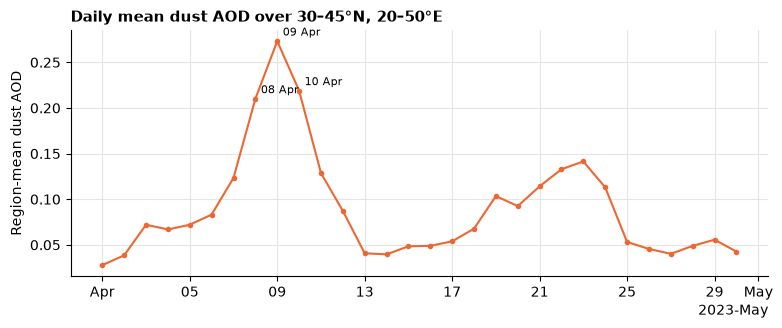

In [4]:
daily = cams.resample(time="1D").mean()
dust_region = daily.duaod550.mean(["latitude", "longitude"])

fig, ax = plt.subplots(figsize=(9, 3.2))
dust_region.plot(ax=ax, color=COLORS[1], marker="o", markersize=3)
ax.set_ylabel("Region-mean dust AOD")
ax.set_xlabel("")
ax.set_title("Daily mean dust AOD over 30–45°N, 20–50°E")
top = dust_region.to_series().nlargest(3)
for day, val in top.items():
    ax.annotate(day.strftime("%d %b"), (day, val), xytext=(4, 4),
                textcoords="offset points", fontsize=8)
save(fig, "03_dust_timeseries.png")
top

There are two dust events: a strong one on **7–11 April** and a weaker one on
**21–23 April**. Let's look at the strongest day together with the ERA5 wind.

## Dust event and the wind field (combining CAMS with ERA5)

CAMS is on a 0.75° grid and ERA5 on a 0.25° grid. To put them on the same map,
we average the ERA5 wind to daily values and interpolate it to the CAMS grid
with `interp_like`.

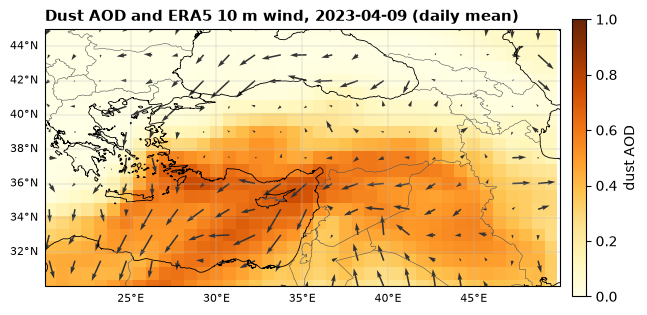

In [5]:
era5 = open_era5()
day = str(top.index[0].date())

wind = era5[["u10", "v10"]].sel(time=day).mean("time")
wind_c = wind.interp_like(cams.isel(time=0))

fig, ax = map_axes(figsize=(8, 4.5))
plot_field(daily.duaod550.sel(time=day), ax, cmap="YlOrBr", label="dust AOD",
           vmin=0, vmax=1)
step = 2
ax.quiver(wind_c.longitude[::step], wind_c.latitude[::step],
          wind_c.u10[::step, ::step], wind_c.v10[::step, ::step],
          transform=PLATE, scale=150, width=0.003, color="#333333")
ax.set_title(f"Dust AOD and ERA5 10 m wind, {day} (daily mean)")
save(fig, "03_dust_event_map.png")

A dust plume covers the whole Eastern Mediterranean and southern Turkey.
Notice that the **10 m wind does not show where the dust came from**: over the
sea it blows from the north-east, but desert dust is usually carried above the
boundary layer, often around 700–500 hPa, where the wind can blow in a different
direction. To follow the transport path we would need ERA5 winds on pressure
levels (or back-trajectories), which are not part of this dataset. This is a
good example of why we must think about *which* variable answers our question.

## PM10 and PM2.5 at Turkish cities

We take the nearest CAMS grid point to each city with `.sel(..., method="nearest")`.
The dashed lines are the **WHO 2021 air-quality guideline** values for the 24-hour
mean: 45 µg m⁻³ for PM10 and 15 µg m⁻³ for PM2.5 (WHO, 2021).

Note: these are model values for a 0.75° (~80 km) grid box, not station
measurements, so they are smoother than what a city station would record.

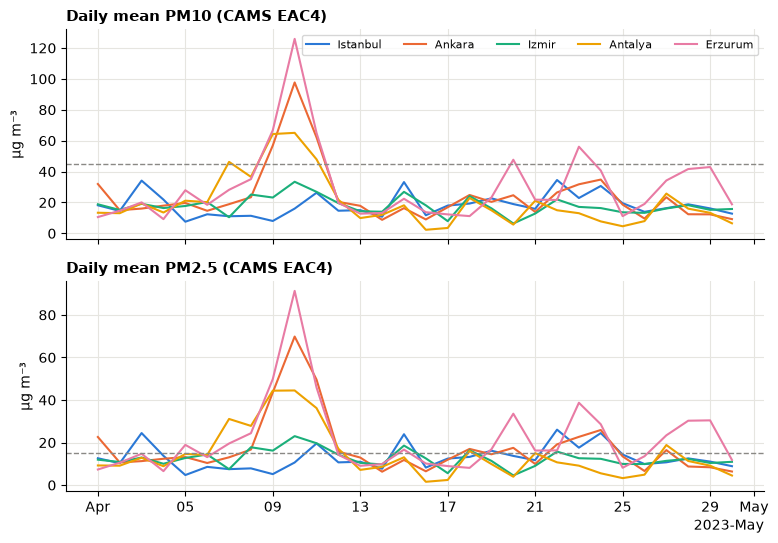

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for i, (city, (lat, lon)) in enumerate(cfg.CITIES.items()):
    point = daily.sel(latitude=lat, longitude=lon, method="nearest")
    point.pm10.plot(ax=axes[0], color=COLORS[i], label=city)
    point.pm2p5.plot(ax=axes[1], color=COLORS[i], label=city)
axes[0].axhline(45, color=GREY, ls="--", lw=1)
axes[1].axhline(15, color=GREY, ls="--", lw=1)
axes[0].set_title("Daily mean PM10 (CAMS EAC4)")
axes[1].set_title("Daily mean PM2.5 (CAMS EAC4)")
axes[0].set_ylabel("µg m⁻³")
axes[1].set_ylabel("µg m⁻³")
axes[1].set_xlabel("")
axes[0].set_xlabel("")
axes[0].legend(ncol=5, fontsize=8, loc="upper right")
save(fig, "03_pm_cities.png")

In [7]:
exceed = (daily.pm10 > 45).sum("time")
print("Days with PM10 above the WHO guideline (nearest grid point):")
for city, (lat, lon) in cfg.CITIES.items():
    n = int(exceed.sel(latitude=lat, longitude=lon, method="nearest"))
    print(f"  {city:9s} {n:2d} days")

Days with PM10 above the WHO guideline (nearest grid point):
  Istanbul   0 days
  Ankara     3 days
  Izmir      0 days
  Antalya    4 days
  Erzurum    5 days


## Is high PM10 explained by dust?

If the PM10 peaks are caused by dust, PM10 should rise together with the dust
AOD. We check this with the correlation between the two at every grid point
(`xr.corr` computes it along the time dimension).

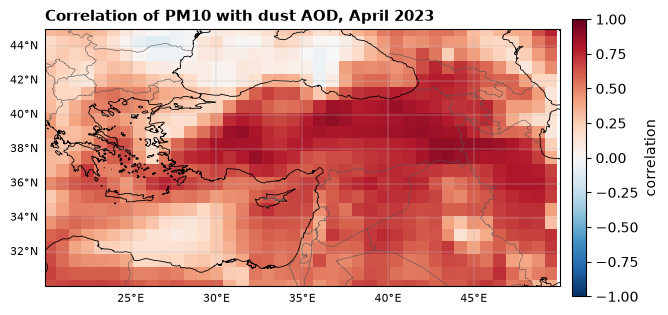

In [8]:
corr = xr.corr(cams.pm10, cams.duaod550, dim="time")

fig, ax = map_axes(figsize=(8, 4.5))
plot_field(corr, ax, cmap="RdBu_r", label="correlation", vmin=-1, vmax=1)
ax.set_title("Correlation of PM10 with dust AOD, April 2023")
save(fig, "03_pm10_dust_correlation.png")

## Summary

- The CAMS reanalysis shows two dust events in April 2023; the stronger one
  (7–11 April) covered the Eastern Mediterranean and southern, central and
  eastern Turkey.
- During this event the daily PM10 at the grid points of Erzurum, Ankara and
  Antalya was about 1.4–2.8 times the WHO daily guideline. Istanbul and Izmir, in the
  north-west, were almost not affected.
- Over Anatolia PM10 and dust AOD are strongly correlated (r > 0.8), so dust
  controls the variations of coarse particle pollution there in this month. Over
  the Balkans and the northern Black Sea the correlation is weak, because other
  sources dominate.
- The heaviest rain of the month (11–13 April, notebook 01) came right after the
  dust event. Dust outbreaks in this region are often followed by rain from the
  same passing low-pressure system, but checking this would need a synoptic
  analysis (pressure-level maps), so here it is only a hypothesis.

**References:** Inness et al. (2019), *Atmos. Chem. Phys.*, 19, 3515–3556;
WHO (2021) Global Air Quality Guidelines. Full list in the README.